# 📧 Spam E-posta Tespiti — v3 (Son hâl): Doğruluğu Artırma Yöntemleri

**Ödev sorusu:** *Elde ettiğimiz doğruluk oranını, makine öğrenmesi algoritmalarında hangi yöntemleri kullanarak artırabiliriz?*

v2'de ölçümü dürüst hâle getirdik (tekrarları temizledik, üçe böldük) ve altı iyileştirme yaptık: hiperparametre arama, özellik sayısı deneyi, eşik ayarı, çeşitli veri, model seçimi, hata analizi. Bu son sürümde **eksik kalan beş yöntemi** ekliyoruz. Her yöntem için önce **literatürde kimin nasıl kullandığına** bakıyoruz, sonra **kendi verimizde deniyoruz**, en sonda hepsini **karışıklık matrisi ve ROC eğrisiyle** karşılaştırıyoruz.

| # | Yöntem | Ne yapar? | Literatürde kim kullanmış? |
|---|---|---|---|
| 1 | Lemmatization / Stemming | Kelimeleri köküne indirir (*meetings → meeting*) | Androutsopoulos ve ark. (2000) |
| 2 | Chi-kare özellik seçimi | Spam/normal ayrımına en çok katkı veren kelimeleri seçer | Eryılmaz, Şahin, Kılıç (2020) — Türkçe e-postalar |
| 3 | Karakter n-gramları | Kelime yerine 3–5 harflik parçalara bakar | Kanaris, Kanaris, Stamatatos (2006) |
| 4 | Topluluk yöntemleri: Voting, Boosting (XGBoost), Stacking | Birden fazla modelin kararını birleştirir | Tian ve ark. (2025), Adnan ve ark. (2024) — ikisi de Enron |
| 5 | Derin öğrenme: DistilBERT | Kelimelerin bağlamını anlayan önceden eğitilmiş dil modeli | Asliyuksek, Tonkal, Kocaoglu (2025) |

### Oyunun kuralı: Adil karşılaştırma
- Hepsi v2'deki **aynı temiz veri** ve **aynı eğitim / doğrulama / test bölmesi** üzerinde denenir.
- Ayar seçimleri **doğrulama** kümesinde yapılır. **Test** kümesine en sonda, bir kez bakılır.
- **Referans model** v2'nin modelidir: TF-IDF (60.000 kelime/kelime çifti) + Doğrusal SVM. Her yöntem bu modele göre ölçülür.
- Asıl ölçütümüz ödevin sorduğu **doğruluk (accuracy)**. Yanına F1, ROC-AUC ve hata sayıları (FP, FN) da koyuyoruz.

> ⚠️ **Gerçekçi beklenti:** Referans modelin doğruluğu zaten ~%98,7. Geriye kalan pay %1,3 kadar. Bu yüzden iyileşmeler **binde birkaç puan** düzeyinde olacak. 5.800 e-postalık test kümesinde binde 1, yaklaşık **6 e-posta** demek.

> ⏳ Colab'da tamamı yaklaşık **10–15 dakika** sürer. En uzun kısımlar karakter n-gramları ve topluluk yöntemleri.

## 0️⃣ Kurulum, veri ve bölme (v2 ile aynı)

Bu bölüm v2'nin 1–3. bölümlerinin kısa hâli: Veriyi indir, temizle, **tekrarları sil**, üçe böl. Ayrıntılı açıklamalar v2 notebook'unda.

Yeni kütüphaneler:
- `xgboost`: Boosting algoritması (Colab'da hazır yüklü)
- `nltk`: Lemmatization ve stemming için dil işleme kütüphanesi (Colab'da hazır yüklü)
- `SelectKBest, chi2`: Chi-kare özellik seçimi
- `VotingClassifier, StackingClassifier`: Topluluk yöntemleri

In [1]:
import re, time, random, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import hstack

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from xgboost import XGBClassifier
import nltk
from nltk.stem import WordNetLemmatizer, PorterStemmer
nltk.download("wordnet", quiet=True); nltk.download("omw-1.4", quiet=True)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RASTGELE = 42
print("Hazır ✅")

Hazır ✅


In [2]:
URL = "https://raw.githubusercontent.com/MWiechmann/enron_spam_data/master/enron_spam_data.zip"
urllib.request.urlretrieve(URL, "enron_spam_data.zip")
zipfile.ZipFile("enron_spam_data.zip").extractall(".")
df = pd.read_csv("enron_spam_data.csv").fillna("")

def temizle(metin):
    metin = metin.lower()
    metin = re.sub(r"http\S+|www\.\S+", " url ", metin)
    metin = re.sub(r"\S+@\S+", " email ", metin)
    metin = re.sub(r"\d+", " sayi ", metin)
    metin = re.sub(r"[^a-z\s]", " ", metin)
    return re.sub(r"\s+", " ", metin).strip()

df["metin"] = (df["Subject"] + " " + df["Message"]).apply(temizle)
df["etiket"] = (df["Spam/Ham"] == "spam").astype(int)
temiz = df[df["metin"] != ""].drop_duplicates(subset="metin").reset_index(drop=True)   # v2'nin 1. iyileştirmesi

X_kalan, X_test, y_kalan, y_test = train_test_split(temiz["metin"], temiz["etiket"], test_size=0.20,
                                                    random_state=RASTGELE, stratify=temiz["etiket"])
X_egitim, X_dog, y_egitim, y_dog = train_test_split(X_kalan, y_kalan, test_size=0.20,
                                                    random_state=RASTGELE, stratify=y_kalan)
print(f"Eğitim {len(X_egitim)} | Doğrulama {len(X_dog)} | Test {len(X_test)}")

Eğitim 18560 | Doğrulama 4640 | Test 5800


### Ölçüm yardımcıları
Her yöntemi aynı şekilde ölçmek için küçük bir fonksiyon yazıyoruz. `puan_al()` modelin her e-postaya verdiği **spam puanını** döndürür. ROC eğrisi için bu puanlar gerekiyor (ilk ödevde öğrendiğimiz gibi, SVM'de `decision_function`, diğerlerinde `predict_proba`).

`SONUCLAR` sözlüğünde her yöntemin **doğrulama** sonucunu biriktireceğiz.

In [3]:
def puan_al(model, X):
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]

def olc(model, X, y):
    tahmin = model.predict(X); puan = puan_al(model, X)
    tn, fp, fn, tp = confusion_matrix(y, tahmin).ravel()
    return {"Accuracy": accuracy_score(y, tahmin), "F1": f1_score(y, tahmin), "ROC-AUC": roc_auc_score(y, puan),
            "FP (normal→spam)": int(fp), "FN (spam kaçtı)": int(fn)}

def tfidf_kelime(metinler_egitim=None, k=60000):
    return TfidfVectorizer(stop_words="english", max_features=k, ngram_range=(1, 2), min_df=2, sublinear_tf=True)

SONUCLAR = {}          # yöntem adı -> doğrulama sonuçları
def kaydet(ad, model, X_d):
    SONUCLAR[ad] = olc(model, X_d, y_dog)
    s = SONUCLAR[ad]
    print(f"{ad:42s} Accuracy={s['Accuracy']:.4f}  F1={s['F1']:.4f}  AUC={s['ROC-AUC']:.5f}  FP={s['FP (normal→spam)']}  FN={s['FN (spam kaçtı)']}")

## 1️⃣ Referans model (v2'nin sonucu)

Bütün yöntemleri bu modelle karşılaştıracağız: 60.000 özellikli kelime TF-IDF'i + Doğrusal SVM (C=1, GridSearchCV'nin v2'de seçtiği değer).

In [4]:
tf_kelime = tfidf_kelime()
A_eg = tf_kelime.fit_transform(X_egitim)
A_dog = tf_kelime.transform(X_dog)
A_test = tf_kelime.transform(X_test)

referans = LinearSVC(C=1.0).fit(A_eg, y_egitim)
kaydet("0. Referans (v2): kelime TF-IDF + SVM", referans, A_dog)

0. Referans (v2): kelime TF-IDF + SVM      Accuracy=0.9873  F1=0.9873  AUC=0.99871  FP=38  FN=21


## 2️⃣ Yöntem 1: Lemmatization ve Stemming

### Ne yapar?
Aynı kelimenin farklı biçimleri bilgisayar için **ayrı kelimelerdir**: *meeting, meetings*; *offer, offers, offered*. Bu yüzden model her birini ayrı ayrı öğrenmek zorunda kalır. Kelimeleri köküne indirirsek, model aynı anlamı tek bir özellikte toplar.

| Yöntem | Nasıl çalışır? | Örnek |
|---|---|---|
| **Stemming** (Porter) | Kelimenin sonundaki ekleri **kurallarla keser**. Hızlıdır ama bazen anlamsız kökler üretir. | *running → run*, *studies → studi* |
| **Lemmatization** (WordNet) | **Sözlüğe bakarak** kelimenin gerçek sözlük biçimini bulur. Daha doğru ama daha yavaş. | *meetings → meeting*, *studies → study* |

### Literatürde
**Androutsopoulos ve ark. (2000)**, spam filtrelemenin ilk sistematik çalışmalarından birinde Ling-Spam veri setinde Naive Bayes ile lemmatization'ı denemiş. Bütün maliyet ayarlarında **en iyi sonuçlar lemmatizer açıkken** alınmış. Stop-word listesi ise sadece bazı ayarlarda katkı sağlamış.

### Bizde deneyelim
Aynı kelimeyi tekrar tekrar işlememek için küçük bir **önbellek** (sözlük) kullanıyoruz. Bu, işlemi çok hızlandırır.

In [5]:
lem, kok = WordNetLemmatizer(), PorterStemmer()
print("Örnekler:", {w: (lem.lemmatize(w), kok.stem(w)) for w in ["meetings", "offers", "studies", "running", "companies"]})
print("          (kelime: (lemma, stem))\n")

onbellek_l, onbellek_s = {}, {}
def lemmatize_et(metin): return " ".join(onbellek_l.setdefault(w, lem.lemmatize(w)) for w in metin.split())
def stem_et(metin):      return " ".join(onbellek_s.setdefault(w, kok.stem(w)) for w in metin.split())

for ad, fonk in [("1a. Lemmatization + SVM", lemmatize_et), ("1b. Stemming + SVM", stem_et)]:
    tf = tfidf_kelime()
    model = LinearSVC(C=1.0).fit(tf.fit_transform(X_egitim.map(fonk)), y_egitim)
    kaydet(ad, model, tf.transform(X_dog.map(fonk)))

Örnekler: {'meetings': ('meeting', 'meet'), 'offers': ('offer', 'offer'), 'studies': ('study', 'studi'), 'running': ('running', 'run'), 'companies': ('company', 'compani')}
          (kelime: (lemma, stem))



1a. Lemmatization + SVM                    Accuracy=0.9871  F1=0.9871  AUC=0.99884  FP=41  FN=19


1b. Stemming + SVM                         Accuracy=0.9862  F1=0.9863  AUC=0.99874  FP=42  FN=22


### Yorum
Lemmatization doğruluğu **artırmadı** (referans 0,9873 → 0,9871), stemming ise biraz **düşürdü** (0,9862). Literatürdeki sonuçla neden farklı?

- **Androutsopoulos ve ark. (2000)** Naive Bayes'e sadece **birkaç yüz kelime** vermişti. Az sayıda özellik varken *offer* ve *offers* gibi biçimleri birleştirmek, her özelliğe daha fazla bilgi toplar. Bizde ise **60.000 özellik** ve 18.500 eğitim e-postası var. Her biçim zaten yeterince sık geçiyor; model hepsini ayrı ayrı öğrenebiliyor.
- **Stemming** bazen farklı anlamları birleştiriyor (*meetings → meet*: "toplantı" ile "buluşmak" aynı köke düşüyor) ve bilgi kaybettiriyor.

**Ders:** Literatürde işe yarayan bir yöntem, **farklı koşullarda** (başka model, başka özellik sayısı) işe yaramayabilir. Bu yüzden her yöntemi kendi verimizde **denemek** zorundayız. "İşe yaramadı" da raporda yazılması gereken bir bulgu.

## 3️⃣ Yöntem 2: Chi-kare (χ²) ile özellik seçimi

### Ne yapar?
60.000 kelimenin hepsi işe yaramaz. Bazıları spam'de de normal e-postada da aynı sıklıkta geçer ve modele sadece **gürültü** katar. Chi-kare testi her kelime için şunu sorar:

> *"Bu kelimenin geçip geçmemesi ile e-postanın spam olup olmaması birbirinden bağımsız mı?"*

Bağımsız değilse (yani kelime spam'de belirgin şekilde daha sık ya da daha seyrek geçiyorsa) chi-kare puanı yüksek çıkar. `SelectKBest(chi2, k=...)` en yüksek puanlı **k** kelimeyi seçer, gerisini atar.

v2'deki özellik sayısı deneyinden farkı: Orada kelimeleri **en sık geçenlere** göre seçmiştik (`max_features`). Burada **spam'i en iyi ayırt edenlere** göre seçiyoruz.

### Literatürde
**Eryılmaz, Şahin ve Kılıç (2020)**, *Bilgisayar Bilimleri ve Mühendisliği Dergisi*'nde Türkçe spam e-postalar üzerinde beş özellik seçim yöntemini karşılaştırmış (chi-kare, bilgi kazancı, belge frekansı, odds oranı, ACC). **Chi-kare en başarılı yöntem** olmuş: SVM (SMO) ile F-ölçütü 0,985'e ulaşmış. Özellik seçimi olmadan Random Forest'ın F-ölçütü 0,514'te kalırken chi-kare ile belirgin şekilde yükselmiş.

### Bizde deneyelim
Farklı **k** değerlerini doğrulama kümesinde deniyoruz:

In [6]:
chi_sonuc = []
for k in [2000, 5000, 10000, 20000, 40000]:
    secici = SelectKBest(chi2, k=k).fit(A_eg, y_egitim)
    m = LinearSVC(C=1.0).fit(secici.transform(A_eg), y_egitim)
    p = m.predict(secici.transform(A_dog))
    chi_sonuc.append({"k (seçilen kelime)": k, "Accuracy": accuracy_score(y_dog, p), "F1": f1_score(y_dog, p)})
chi_sonuc = pd.DataFrame(chi_sonuc)
display(chi_sonuc.style.format({"Accuracy": "{:.4f}", "F1": "{:.4f}"}).highlight_max(subset=["Accuracy"], color="#b6e3b6"))

EN_IYI_CHI_K = int(chi_sonuc.loc[chi_sonuc["Accuracy"].idxmax(), "k (seçilen kelime)"])
secici_chi = SelectKBest(chi2, k=EN_IYI_CHI_K).fit(A_eg, y_egitim)
model_chi = LinearSVC(C=1.0).fit(secici_chi.transform(A_eg), y_egitim)
kaydet(f"2. Chi-kare (k={EN_IYI_CHI_K}) + SVM", model_chi, secici_chi.transform(A_dog))

print("\nChi-kare puanı en yüksek 15 kelime:")
isimler = np.array(tf_kelime.get_feature_names_out())
print(", ".join(isimler[np.argsort(secici_chi.scores_)[::-1][:15]]))

,k (seçilen kelime),Accuracy,F1
0,2000,0.9810,0.9813
1,5000,0.9834,0.9835
2,10000,0.9849,0.9850
3,20000,0.9864,0.9865
4,40000,0.9871,0.9871


2. Chi-kare (k=40000) + SVM                Accuracy=0.9871  F1=0.9871  AUC=0.99860  FP=39  FN=21

Chi-kare puanı en yüksek 15 kelime:
enron, ect, vince, hou ect, hou, cc, ect ect, pm, sayi pm, attached, subject, thanks, http, louise, let know


### Yorum
Chi-kare ile kelime sayısını azalttıkça doğruluk **düşüyor**. En iyi değer (k = 40.000) referansla neredeyse aynı (0,9871). Yani bizim modelimizde özellik seçimi doğruluğu artırmadı.

Neden? Doğrusal SVM, eğitim sırasında işe yaramayan kelimelere zaten **çok küçük ağırlıklar** veriyor (düzenlileştirme). Onları atmak modele yeni bir şey kazandırmıyor. Chi-kare asıl olarak **çok özellikle zorlanan** modellerde (Random Forest, kNN) fark yaratır. Eryılmaz ve ark.'nın çalışmasında da en büyük sıçrama Random Forest'ta görülmüştü.

Yine de iki faydası var:
1. **Daha küçük model:** 20.000 kelimeyle de doğruluk sadece binde 1 düşüyor. Hız ve bellek önemliyse bu iyi bir takas.
2. **Açıklanabilirlik:** En ayırt edici kelimelere bak: *enron, ect, vince, hou (Houston), louise*... Bunların çoğu **Enron'a özgü**. Model "spam nedir"den çok "Enron e-postası neye benzer"i öğreniyor. v2'deki genelleme testinde SpamAssassin'de başarının düşmesinin sebebi tam olarak bu.

## 4️⃣ Yöntem 3: Karakter n-gramları

### Ne yapar?
Şimdiye kadar e-postaları **kelimelere** böldük. Karakter n-gramı ise metni **3–5 harflik kayan parçalara** böler:

> *"viagra"* → `vi`, `via`, `iag`, `agr`, `gra`, `ra` ... (3-gram'lar), `viag`, `iagr`, ... (4-gram'lar)

Bunun iki faydası var:
1. **Bozuk yazımlara dayanıklılık:** Spamciler filtreyi atlatmak için *"viaagra"*, *"v iagra"*, *"frree"* gibi yazımlar kullanır. Kelime tabanlı model bunları hiç görmediği yeni kelimeler sanar. Karakter n-gramlarının çoğu ise aynı kalır (`via`, `agr`, `gra`).
2. **Kelime içi ipuçları:** Ekler, kökler ve kelime parçaları da özellik olur.

`analyzer="char_wb"` parçaları kelime sınırları içinde üretir (kelimenin başına ve sonuna boşluk koyarak).

### Literatürde
**Kanaris, Kanaris ve Stamatatos (2006)**, Ling-Spam veri setinde e-postaları "karakter n-gramı torbası" olarak temsil edip SVM ile sınıflandırmış. Hiçbir dil işleme (lemmatization, stop-word) kullanmadan **ikili 4-gram'lar** en iyi sonucu vermiş: spam duyarlılığı %98,5, kesinliği %99,6. Düşük ve orta maliyet ayarlarında kelime tabanlı Naive Bayes ve Stacking yöntemlerini geride bırakmış.

### Bizde deneyelim
Karakter özelliklerini tek başına ve kelime özellikleriyle **birleştirerek** (`hstack` = yan yana eklemek) deniyoruz.

> ⏳ Bu hücre birkaç dakika sürebilir: 100.000 karakter n-gramı çıkarılıyor.

In [7]:
tf_karakter = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=100000, min_df=2, sublinear_tf=True)
K_eg = tf_karakter.fit_transform(X_egitim)
K_dog = tf_karakter.transform(X_dog)
K_test = tf_karakter.transform(X_test)

model_kar = LinearSVC(C=1.0).fit(K_eg, y_egitim)
kaydet("3a. Karakter n-gram (3–5) + SVM", model_kar, K_dog)

# Kelime + karakter özelliklerini yan yana birleştir
AK_eg, AK_dog, AK_test = hstack([A_eg, K_eg]).tocsr(), hstack([A_dog, K_dog]).tocsr(), hstack([A_test, K_test]).tocsr()
model_kk = LinearSVC(C=1.0).fit(AK_eg, y_egitim)
kaydet("3b. Kelime + karakter n-gram + SVM", model_kk, AK_dog)
print("\nBirleşik özellik sayısı:", AK_eg.shape[1])

3a. Karakter n-gram (3–5) + SVM            Accuracy=0.9897  F1=0.9897  AUC=0.99919  FP=36  FN=12


3b. Kelime + karakter n-gram + SVM         Accuracy=0.9894  F1=0.9895  AUC=0.99919  FP=36  FN=13

Birleşik özellik sayısı: 160000


### Dayanıklılık testi: Bozuk yazımlı spam'ler
Karakter n-gramlarının asıl iddiası **bozuk yazımlara dayanıklılık**. Bunu test edelim: Test kümesindeki spam'lerde kelimelerin %30'unda rastgele bir harfi **tekrarlayalım** ya da iki harfin **yerini değiştirelim** (*"money" → "monney"*, *"offer" → "ofefr"*). Sonra iki modelin bu spam'lerin ne kadarını yakaladığına bakalım.

In [8]:
rng = random.Random(RASTGELE)
def boz(metin, oran=0.3):
    kelimeler = []
    for w in metin.split():
        if len(w) > 3 and rng.random() < oran:
            i = rng.randrange(1, len(w) - 1)
            w = w[:i] + w[i] + w[i:] if rng.random() < 0.5 else w[:i] + w[i + 1] + w[i] + w[i + 2:]
        kelimeler.append(w)
    return " ".join(kelimeler)

spamler = X_test[y_test == 1]
bozuk = spamler.map(boz)
print("Örnek bozuk spam:", bozuk.iloc[3][:160], "...\n")

def yakala(model, metinler, karakter_var):
    X = tf_kelime.transform(metinler)
    if karakter_var:
        X = hstack([X, tf_karakter.transform(metinler)]).tocsr()
    return (model.predict(X) == 1).mean()

dayaniklilik = pd.DataFrame({
    "Normal spam'ler": [yakala(referans, spamler, False), yakala(model_kk, spamler, True)],
    "Bozuk yazımlı spam'ler": [yakala(referans, bozuk, False), yakala(model_kk, bozuk, True)],
}, index=["Sadece kelime (referans)", "Kelime + karakter n-gram"])
dayaniklilik["Kayıp"] = dayaniklilik["Normal spam'ler"] - dayaniklilik["Bozuk yazımlı spam'ler"]
dayaniklilik.style.format("{:.1%}")

Örnek bozuk spam: valiium diazeppam odrer valium direcctly froom here woould you like to orrder yoour medication online and haave it shipped to your door overniight join the tenn ...



,Normal spam'ler,Bozuk yazımlı spam'ler,Kayıp
Sadece kelime (referans),99.7%,99.6%,0.1%
Kelime + karakter n-gram,99.6%,99.7%,-0.0%


### Yorum
**Tek başına en büyük katkıyı veren yöntem bu.** Karakter n-gramları doğruluğu 0,9873'ten **0,9897**'ye çıkardı ve kaçan spam sayısını (FN) **21'den 12'ye** indirdi. Kelime ve karakter özelliklerini birleştirmek ek bir fayda sağlamadı (0,9894), çünkü 3–5 harflik parçalar kısa kelimeleri zaten kapsıyor.

**Dayanıklılık testi beklenmedik bir sonuç verdi:** Kelimelerin %30'unu bozmak **iki modeli de** neredeyse hiç etkilemedi (%99,7 → %99,6). Sebebi: Spam e-postalar uzun ve **çok sayıda ipucu** içeriyor. Kelimelerin %30'u bozulsa bile kalan %70 spam olduğunu ele vermeye yetiyor. Yani bu veri setinde karakter n-gramlarının kazancı bozuk yazımlardan değil, **kelime içi ipuçlarından** geliyor: ekler, kelime parçaları ve eğitimde hiç görülmemiş nadir kelimelerin tanıdık parçaları.

> 🧪 **Sen dene:** Dayanıklılık hücresinde `boz(metin, oran=0.3)` satırındaki `0.3`'ü `0.7` ya da `0.9` yap. Kelimelerin çoğu bozulunca iki model arasında fark açılıyor mu?

## 5️⃣ Yöntem 4: Topluluk yöntemleri (Ensemble Learning)

### Temel fikir: "Kalabalığın bilgeliği"
Tek bir uzman yerine birkaç farklı uzmana danışmak genellikle daha iyi karar verir. Ama bir şartla: Uzmanlar **farklı türde hatalar** yapmalı. Hepsi aynı yerde yanılıyorsa birleştirmek işe yaramaz.

Üç temel topluluk yöntemi var:

| Yöntem | Nasıl birleştirir? | Benzetme |
|---|---|---|
| **Voting (oylama)** | Her model oy verir, çoğunluk kazanır | Jüri oylaması |
| **Boosting** (XGBoost) | Modeller **sırayla** eğitilir; her yeni model, öncekilerin **hata yaptığı** örneklere odaklanır | Öğrencinin her denemede sadece yanlış yaptığı soruları çalışması |
| **Stacking (yığma)** | Temel modellerin tahminleri, **ikinci seviye bir modele** (meta-öğrenici) girdi olur. Meta-öğrenici hangi modele ne zaman güveneceğini öğrenir. | Bir yöneticinin danışmanlarının görüşlerini, kimin hangi konuda daha isabetli olduğunu bilerek tartması |

> Random Forest da aslında bir topluluk yöntemidir (**Bagging**): Çok sayıda karar ağacı paralel eğitilip oylanır. İlk ödevde bunu zaten kullandık.

### Literatürde
- **Tian ve ark. (2025), *PLOS One*:** Enron (Wiechmann'ın CSV sürümü, yani bizim kullandığımız veri) ve bir Kaggle veri setiyle TF-IDF özellikleri üzerinde Naive Bayes, kNN, Lojistik Regresyon ve XGBoost'u **Stacking** ile birleştirmiş (meta-öğrenici: XGBoost). Ayar yapmadan önceki sonuçlarda en iyi tek model XGBoost %96,4 doğrulukta kalırken, Stacking **%97,8**'e çıkmış.
- **Adnan ve ark. (2024), *International Journal of Information Security*:** SpamAssassin + Enron birleşiminde Lojistik Regresyon, karar ağacı, kNN, Naive Bayes ve AdaBoost'u Stacking ile birleştirmiş (meta-öğrenici: Lojistik Regresyon). En iyi tek model Lojistik Regresyon %98,1 doğrulukta, Stacking **%98,8**.

İki çalışmada da Stacking en iyi tek modeli **yaklaşık 0,7–1,4 puan** geçmiş.

### Bizde deneyelim
Temel modeller olarak üç **farklı mantıkla çalışan** algoritma seçiyoruz: SVM (geometrik sınır), Lojistik Regresyon (olasılık + ağırlıklar), Naive Bayes (kelime olasılıkları). Ayarları v2'deki GridSearchCV sonuçlarından alıyoruz.

XGBoost 60.000 özellikle çok yavaş çalışacağı için ona chi-kare ile seçilmiş **5.000 kelimeyi** veriyoruz. Bu, iki yöntemin birlikte kullanılmasına da güzel bir örnek.

> ⏳ Bu bölüm Colab'da 4–6 dakika sürebilir.

In [9]:
def temel_modeller():
    return [("svm", LinearSVC(C=1.0)),
            ("lr",  LogisticRegression(C=30, solver="liblinear", max_iter=2000)),
            ("nb",  MultinomialNB(alpha=0.03))]

# 4a. Voting: çoğunluk oyu
t0 = time.time()
voting = VotingClassifier(temel_modeller(), voting="hard").fit(A_eg, y_egitim)
p = voting.predict(A_dog)
SONUCLAR["4a. Voting (SVM + LR + NB)"] = {"Accuracy": accuracy_score(y_dog, p), "F1": f1_score(y_dog, p), "ROC-AUC": np.nan,
    "FP (normal→spam)": int(((p == 1) & (y_dog == 0)).sum()), "FN (spam kaçtı)": int(((p == 0) & (y_dog == 1)).sum())}
print(f"4a. Voting  Accuracy={SONUCLAR['4a. Voting (SVM + LR + NB)']['Accuracy']:.4f}  ({time.time()-t0:.0f} sn)")
print("   (Sert oylama sadece 0/1 oy verdiği için ROC eğrisi çizilemez.)\n")

# 4b. Boosting: XGBoost (chi-kare ile seçilmiş 5.000 kelime)
t0 = time.time()
secici_5k = SelectKBest(chi2, k=5000).fit(A_eg, y_egitim)
X5_eg, X5_dog, X5_test = secici_5k.transform(A_eg), secici_5k.transform(A_dog), secici_5k.transform(A_test)
xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method="hist",
                    n_jobs=-1, eval_metric="logloss", random_state=RASTGELE)
xgb.fit(X5_eg, y_egitim)
kaydet("4b. Boosting: XGBoost (chi-kare 5.000)", xgb, X5_dog)
print(f"   ({time.time()-t0:.0f} sn)\n")

# 4c. Stacking: temel modellerin puanları -> Lojistik Regresyon meta-öğrenici
t0 = time.time()
stacking = StackingClassifier(temel_modeller(), final_estimator=LogisticRegression(), cv=5).fit(A_eg, y_egitim)
kaydet("4c. Stacking (SVM + LR + NB → LR)", stacking, A_dog)
print(f"   ({time.time()-t0:.0f} sn)")
print("\nMeta-öğrenicinin temel modellere verdiği ağırlıklar (SVM, LR, NB):",
      np.round(stacking.final_estimator_.coef_[0], 2))

4a. Voting  Accuracy=0.9879  (1 sn)
   (Sert oylama sadece 0/1 oy verdiği için ROC eğrisi çizilemez.)



4b. Boosting: XGBoost (chi-kare 5.000)     Accuracy=0.9716  F1=0.9720  AUC=0.99607  FP=105  FN=27
   (40 sn)



4c. Stacking (SVM + LR + NB → LR)          Accuracy=0.9892  F1=0.9893  AUC=0.99884  FP=32  FN=18
   (3 sn)

Meta-öğrenicinin temel modellere verdiği ağırlıklar (SVM, LR, NB): [4.69 1.37 3.06]


### Stacking içeride ne yapıyor?
`cv=5` önemli: Meta-öğrenicinin eğitim verisi, temel modellerin **görmediği** e-postalardaki tahminlerinden oluşur. Eğitim verisi 5 parçaya bölünür, her parça için temel modeller diğer 4 parçayla eğitilip o parçayı tahmin eder. Böylece meta-öğrenici, temel modellerin **ezberlediği** değil **gerçekten tahmin ettiği** puanlardan öğrenir. Bu da v2'deki veri sızıntısı dersinin bir uygulaması.

Son satırdaki ağırlıklar, meta-öğrenicinin hangi modele ne kadar güvendiğini gösteriyor.

### Yorum
Üç topluluk yöntemi çok farklı sonuç verdi:

- **Voting: küçük kazanç** (0,9873 → 0,9879). Üç model çoğunlukla **aynı e-postalarda** yanıldığı için çoğunluk oyu kararı nadiren değiştiriyor. Topluluk yöntemlerinin şartını hatırla: Modeller **farklı** hatalar yapmalı.
- **XGBoost: belirgin şekilde kötü** (0,9716; FP = 105). Karar ağacı tabanlı modeller seyrek metin verisinde zayıf kalıyor. v2'de Random Forest'ta da aynı şeyi görmüştük. Bu, literatürle de uyumlu: Tian ve ark.'nın çalışmasında da XGBoost tek başına %96,4'te kalmıştı.
- **Stacking: belirgin kazanç** (0,9873 → **0,9892**; normal maili spam sanma sayısı 38 → 32). Meta-öğrenici modelleri basitçe oylatmak yerine **kime ne kadar güveneceğini** öğreniyor.

Meta-öğrenicinin ağırlıklarına bak: **Naive Bayes**, tek başına en zayıf model olmasına rağmen yüksek ağırlık almış. Çünkü SVM'den **farklı türde hatalar** yapıyor ve onu iyi tamamlıyor. Stacking'in gücü buradan geliyor: **çeşitlilik**.

Literatürde Stacking'in kazancı 0,7–1,4 puandı, bizde 0,2 puan. Fark doğal: Onların başlangıç modelleri %96–98'deydi, bizimki zaten %98,7. Tavana yaklaştıkça kazanç küçülüyor.

## 6️⃣ En iyileri birleştirmek: Karakter n-gram + Stacking

Şimdiye kadar her yöntemi **tek başına** referansa ekledik. Doğal bir sonraki adım, en çok katkı verenleri **birlikte** kullanmak: Kelime + karakter özellikleri üzerinde Stacking.

In [10]:
t0 = time.time()
stacking_kk = StackingClassifier(temel_modeller(), final_estimator=LogisticRegression(), cv=5).fit(AK_eg, y_egitim)
kaydet("5. Kelime + karakter + Stacking", stacking_kk, AK_dog)
print(f"   ({time.time()-t0:.0f} sn)")

5. Kelime + karakter + Stacking            Accuracy=0.9901  F1=0.9901  AUC=0.99924  FP=27  FN=19
   (60 sn)


## 7️⃣ Yöntem 5: Derin öğrenme — DistilBERT (isteğe bağlı, GPU gerekir)

### Ne yapar?
Şimdiye kadarki bütün yöntemler **kelime torbası** mantığıyla çalışıyor: Kelimelerin sırasına bakmıyorlar. *"Bu bir dolandırıcılık değil"* ile *"Bu bir dolandırıcılık"* neredeyse aynı görünüyor.

**BERT** (Google, 2018) milyarlarca kelimelik metinle önceden eğitilmiş bir **Transformer** dil modelidir. Her kelimeyi cümledeki diğer kelimelerle birlikte değerlendirir (**dikkat mekanizması**, attention). **DistilBERT** onun %40 daha küçük ve %60 daha hızlı, ama başarısının ~%97'sini koruyan "damıtılmış" sürümüdür. Biz bu hazır modeli alıp spam verimizle **ince ayar (fine-tuning)** yapıyoruz: Dil bilgisi hazır, sadece "spam nedir"i öğretiyoruz.

### Literatürde
**Asliyuksek, Tonkal ve Kocaoglu (2025), *Electronics*:** Enron dahil yedi spam veri setini birleştirip (81.586 e-posta) DistilBERT'i 2 epoch ince ayarlamış (en fazla 256 token). DistilBERT **%99,57** doğruluğa ulaşmış; en iyi klasik model (Random Forest, CountVectorizer/TF-IDF ile) %98,85'te kalmış. DistilBERT'e metin uzunluğu, büyük harf oranı gibi yapısal özellikler eklenince **%99,62**. Yazarlar en iyi modeller arasındaki farkların örneklem değişkenliği sınırları içinde olduğunu da not etmiş.

Ayrıca v2'de gördüğümüz gibi **Sahmoud & Mikki (2022)** BERT-base ile Enron'da F1 %98,62, **Tang & Li (2024)** %98,68 elde etmiş.

### Nasıl çalıştırılır?
Bu bölüm **GPU** ister ve 10–15 dakika sürer. Kod değiştirmen gerekmiyor: Hücre GPU olup olmadığına kendisi bakar.
- **GPU açıksa** DistilBERT otomatik olarak eğitilir ve sonuçları bütün tablolara eklenir.
- **GPU kapalıysa** bu bölüm atlanır, notebook'un geri kalanı normal çalışır.

GPU'yu açmak için: **Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU → Kaydet**, sonra **Çalışma zamanı → Tümünü çalıştır**.

Süreyi kısa tutmak için eğitimi 6.000 e-postalık bir alt kümede, 2 epoch ve en fazla 256 token ile yapıyoruz. Değerlendirme diğer yöntemlerle **aynı doğrulama ve test kümelerinde** yapılıyor. Böylece DistilBERT ablasyon tablosuna, final karışıklık matrislerine ve ROC eğrilerine kendiliğinden ekleniyor. Tam veriyle eğitim daha iyi sonuç verebilir.

> ⚠️ Bu hücre isteğe bağlı olduğu için bu notebook'un kaydedilmiş çıktılarında sonucu yok. Kendi Colab'ında GPU ile çalıştırınca sonuç bütün tablolara ve grafiklere otomatik eklenir.

In [11]:
BERT_CALISTIR = "otomatik"  # "otomatik": GPU varsa çalışır, yoksa atlanır. True: her durumda çalışır. False: hiç çalışmaz.
BERT_EGITIM_SAYISI = 6000   # eğitimde kullanılacak e-posta sayısı (GPU güçlüyse artırabilirsin)
BERT_TEST = None            # test sonuçları burada saklanacak (final bölümünde kullanılıyor)

try:
    import torch
    GPU_VAR = torch.cuda.is_available()
except ImportError:
    GPU_VAR = False
if BERT_CALISTIR == "otomatik":
    BERT_CALISTIR = GPU_VAR
    print("GPU bulundu → DistilBERT çalışacak." if GPU_VAR else
          "GPU bulunamadı → DistilBERT atlanacak. (Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU)")

def bert_metrikleri(y, puan):
    tahmin = (puan > 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, tahmin).ravel()
    return tahmin, {"Accuracy": accuracy_score(y, tahmin), "F1": f1_score(y, tahmin), "ROC-AUC": roc_auc_score(y, puan),
                    "FP (normal→spam)": int(fp), "FN (spam kaçtı)": int(fn)}

if BERT_CALISTIR:
    import torch
    from torch.utils.data import DataLoader, TensorDataset
    from transformers import AutoTokenizer, AutoModelForSequenceClassification

    torch.manual_seed(RASTGELE)
    cihaz = "cuda" if torch.cuda.is_available() else "cpu"
    print("Cihaz:", cihaz, "" if cihaz == "cuda" else "← GPU yok! Çok yavaş olur; Çalışma zamanı türünü T4 GPU yap.")
    AD = "distilbert-base-uncased"
    tok = AutoTokenizer.from_pretrained(AD)
    bert = AutoModelForSequenceClassification.from_pretrained(AD, num_labels=2).to(cihaz)

    def veri_seti(metinler, etiketler):
        kod = tok(list(metinler), truncation=True, max_length=256, padding="max_length", return_tensors="pt")
        return TensorDataset(kod["input_ids"], kod["attention_mask"], torch.tensor(list(etiketler)))

    def bert_puanla(metinler, etiketler):
        bert.eval(); puanlar = []
        with torch.no_grad():
            for ids, maske, _ in DataLoader(veri_seti(metinler, etiketler), batch_size=64):
                logit = bert(input_ids=ids.to(cihaz), attention_mask=maske.to(cihaz)).logits
                puanlar.append(torch.softmax(logit, -1)[:, 1].cpu().numpy())
        return np.concatenate(puanlar)

    # 1) İnce ayar (fine-tuning)
    alt = X_egitim.sample(BERT_EGITIM_SAYISI, random_state=RASTGELE)
    egitim_dl = DataLoader(veri_seti(alt, y_egitim.loc[alt.index]), batch_size=16, shuffle=True)
    opt = torch.optim.AdamW(bert.parameters(), lr=5e-5)
    t_bas = time.time()
    for epoch in range(2):
        bert.train(); t0 = time.time(); toplam = 0.0
        for adim, (ids, maske, y) in enumerate(egitim_dl, 1):
            opt.zero_grad()
            kayip = bert(input_ids=ids.to(cihaz), attention_mask=maske.to(cihaz), labels=y.to(cihaz)).loss
            kayip.backward(); opt.step(); toplam += kayip.item()
            if adim % 100 == 0:
                print(f"  epoch {epoch + 1} · adım {adim}/{len(egitim_dl)} · ortalama kayıp {toplam / adim:.4f}")
        print(f"Epoch {epoch + 1} bitti ({time.time() - t0:.0f} sn), ortalama kayıp {toplam / len(egitim_dl):.4f}")
    egitim_suresi = time.time() - t_bas

    # 2) Doğrulama kümesi → ablasyon tablosu
    ad_bert = f"6. DistilBERT ({BERT_EGITIM_SAYISI} e-posta, 2 epoch)"
    _, SONUCLAR[ad_bert] = bert_metrikleri(y_dog, bert_puanla(X_dog, y_dog))

    # 3) Test kümesi → final karışıklık matrisi ve ROC eğrisi
    bert_test_puan = bert_puanla(X_test, y_test)
    bert_test_tahmin, bert_test_sonuc = bert_metrikleri(y_test, bert_test_puan)
    BERT_TEST = (bert_test_tahmin, bert_test_puan, bert_test_sonuc)

    print("\n===== DistilBERT ÖZET =====")
    print(f"Eğitim: {BERT_EGITIM_SAYISI} e-posta, 2 epoch, {egitim_suresi / 60:.1f} dakika ({cihaz})")
    for kume, s in [("Doğrulama", SONUCLAR[ad_bert]), ("Test", bert_test_sonuc)]:
        print(f"{kume:10s} Accuracy={s['Accuracy']:.4f}  F1={s['F1']:.4f}  AUC={s['ROC-AUC']:.5f}  "
              f"FP={s['FP (normal→spam)']}  FN={s['FN (spam kaçtı)']}")
else:
    print("DistilBERT atlandı. Çalıştırmak için GPU'yu aç ve notebook'u baştan çalıştır.")

GPU bulunamadı → DistilBERT atlanacak. (Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU)
DistilBERT atlandı. Çalıştırmak için GPU'yu aç ve notebook'u baştan çalıştır.


## 8️⃣ Ablasyon tablosu: Hangi yöntem ne kadar katkı sağladı?

**Ablasyon çalışması**, bir sisteme parçaları tek tek ekleyip (ya da çıkarıp) her parçanın katkısını ölçmektir. Aşağıdaki tablo bütün yöntemlerin **doğrulama** kümesindeki sonuçlarını referansla karşılaştırıyor. "Fark" sütunu referansa göre doğruluk değişimini gösteriyor; "Hata farkı" ise kaç e-postanın daha doğru (−) ya da daha yanlış (+) sınıflandırıldığını.

,Accuracy,F1,ROC-AUC,FP (normal→spam),FN (spam kaçtı),Fark (Accuracy),Toplam hata,Hata farkı
0. Referans (v2): kelime TF-IDF + SVM,0.9873,0.9873,0.99871,38,21,+0.0000,59,0
1a. Lemmatization + SVM,0.9871,0.9871,0.99884,41,19,-0.0002,60,1
1b. Stemming + SVM,0.9862,0.9863,0.99874,42,22,-0.0011,64,5
2. Chi-kare (k=40000) + SVM,0.9871,0.9871,0.99860,39,21,-0.0002,60,1
3a. Karakter n-gram (3–5) + SVM,0.9897,0.9897,0.99919,36,12,+0.0024,48,-11
3b. Kelime + karakter n-gram + SVM,0.9894,0.9895,0.99919,36,13,+0.0022,49,-10
4a. Voting (SVM + LR + NB),0.9879,0.9880,—,38,18,+0.0006,56,-3
4b. Boosting: XGBoost (chi-kare 5.000),0.9716,0.9720,0.99607,105,27,-0.0157,132,73
4c. Stacking (SVM + LR + NB → LR),0.9892,0.9893,0.99884,32,18,+0.0019,50,-9
5. Kelime + karakter + Stacking,0.9901,0.9901,0.99924,27,19,+0.0028,46,-13


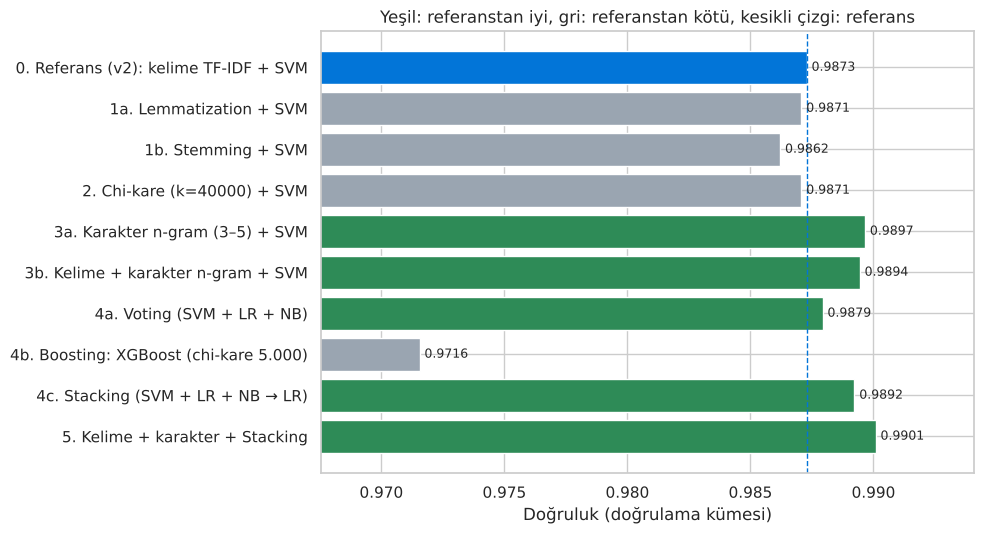

Doğrulama kümesinde en iyi yöntem: 5. Kelime + karakter + Stacking


In [12]:
ablasyon = pd.DataFrame(SONUCLAR).T
ref_acc = ablasyon.iloc[0]["Accuracy"]
ref_hata = ablasyon.iloc[0]["FP (normal→spam)"] + ablasyon.iloc[0]["FN (spam kaçtı)"]
ablasyon["Fark (Accuracy)"] = ablasyon["Accuracy"] - ref_acc
ablasyon["Toplam hata"] = (ablasyon["FP (normal→spam)"] + ablasyon["FN (spam kaçtı)"]).astype(int)
ablasyon["Hata farkı"] = (ablasyon["Toplam hata"] - ref_hata).astype(int)
display(ablasyon.style.format({"Accuracy": "{:.4f}", "F1": "{:.4f}", "ROC-AUC": "{:.5f}", "Fark (Accuracy)": "{:+.4f}",
                               "FP (normal→spam)": "{:.0f}", "FN (spam kaçtı)": "{:.0f}"}, na_rep="—")
        .background_gradient(subset=["Fark (Accuracy)"], cmap="RdYlGn", vmin=-0.006, vmax=0.006))

renk = ["#9aa5b1" if d < 0 else "#2e8b57" for d in ablasyon["Fark (Accuracy)"]]
renk[0] = "#0275d8"
plt.figure(figsize=(10, 0.45 * len(ablasyon) + 1))
plt.barh(ablasyon.index, ablasyon["Accuracy"], color=renk)
for i, v in enumerate(ablasyon["Accuracy"]):
    plt.text(v + 0.0002, i, f"{v:.4f}", va="center", fontsize=9)
plt.axvline(ref_acc, color="#0275d8", ls="--", lw=1)
plt.xlim(ablasyon["Accuracy"].min() - 0.004, min(1, ablasyon["Accuracy"].max() + 0.004))
plt.gca().invert_yaxis(); plt.xlabel("Doğruluk (doğrulama kümesi)")
plt.title("Yeşil: referanstan iyi, gri: referanstan kötü, kesikli çizgi: referans")
plt.tight_layout(); plt.show()

EN_IYI = ablasyon["Accuracy"].astype(float).idxmax()
print("Doğrulama kümesinde en iyi yöntem:", EN_IYI)

### Yorum
Doğrulama kümesinde tablo net:

| Sonuç | Yöntemler |
|---|---|
| ✅ Belirgin katkı | Karakter n-gram (+0,0024), Stacking (+0,0019) |
| ➖ Etkisiz | Lemmatization, chi-kare, Voting (±0,0006) |
| ❌ Kötüleştirdi | Stemming (−0,0011), XGBoost (−0,0157) |

**İkisini birleştirmek** (kelime + karakter + Stacking) en iyi sonucu verdi: **0,9901** (+0,0028). Toplam hata **59'dan 46'ya** indi (%22 azalma).

Dikkat: Birleşimin kazancı iki yöntemin kazançlarının toplamı değil (0,0024 + 0,0019 ≠ 0,0028). Çünkü iki yöntem **bazı hataları ortak** düzeltiyor. Yöntemler üst üste eklenince her yeni yöntemin katkısı küçülür.

## 9️⃣ Final: Test kümesinde karışıklık matrisleri ve ROC eğrileri

Bütün seçimler doğrulama kümesinde yapıldı. Şimdi her yöntemi **test kümesinde bir kez** ölçüyoruz ve iki araçla karşılaştırıyoruz:

- **Karışıklık matrisi:** Her yöntemin **hangi tür hatayı** kaç kez yaptığını gösterir. Sağ üst hücre FP (normal mail spam'e gitti), sol alt hücre FN (spam kaçtı).
- **ROC eğrisi:** Her yöntemin **bütün eşik değerlerindeki** performansını gösterir. Eğri sol üst köşeye ne kadar yakınsa o kadar iyi. AUC değeri bunu tek sayıya indirir.

In [13]:
test_modelleri = {
    "Referans (v2)":                 (referans,    A_test),
    "Lemmatization":                 None,   # aşağıda ayrıca hesaplanıyor
    f"Chi-kare (k={EN_IYI_CHI_K})":  (model_chi,   secici_chi.transform(A_test)),
    "Kelime + karakter n-gram":      (model_kk,    AK_test),
    "XGBoost (boosting)":            (xgb,         X5_test),
    "Stacking":                      (stacking,    A_test),
    "Kelime + karakter + Stacking":  (stacking_kk, AK_test),
}
# Lemmatization modelini test için yeniden kur (yukarıda döngü içinde kalmıştı)
tf_lem = tfidf_kelime(); X_eg_lem = X_egitim.map(lemmatize_et)
model_lem = LinearSVC(C=1.0).fit(tf_lem.fit_transform(X_eg_lem), y_egitim)
test_modelleri["Lemmatization"] = (model_lem, tf_lem.transform(X_test.map(lemmatize_et)))

test_sonuc, test_puan, test_tahmin = {}, {}, {}
for ad, (model, X) in test_modelleri.items():
    test_tahmin[ad] = model.predict(X); test_puan[ad] = puan_al(model, X)
    test_sonuc[ad] = olc(model, X, y_test)
test_sonuc["Voting"] = None
test_tahmin["Voting"] = voting.predict(A_test)
tn, fp, fn, tp = confusion_matrix(y_test, test_tahmin["Voting"]).ravel()
test_sonuc["Voting"] = {"Accuracy": accuracy_score(y_test, test_tahmin["Voting"]), "F1": f1_score(y_test, test_tahmin["Voting"]),
                        "ROC-AUC": np.nan, "FP (normal→spam)": int(fp), "FN (spam kaçtı)": int(fn)}

# DistilBERT çalıştırıldıysa onu da ekle
if BERT_TEST is not None:
    test_tahmin["DistilBERT"], test_puan["DistilBERT"], test_sonuc["DistilBERT"] = BERT_TEST

test_tablo = pd.DataFrame(test_sonuc).T
test_tablo["Toplam hata"] = (test_tablo["FP (normal→spam)"] + test_tablo["FN (spam kaçtı)"]).astype(int)
test_tablo = test_tablo.sort_values("Accuracy", ascending=False)
display(test_tablo.style.format({"Accuracy": "{:.4f}", "F1": "{:.4f}", "ROC-AUC": "{:.5f}",
                                 "FP (normal→spam)": "{:.0f}", "FN (spam kaçtı)": "{:.0f}"}, na_rep="—")
        .highlight_max(subset=["Accuracy", "F1"], color="#b6e3b6").highlight_min(subset=["Toplam hata"], color="#b6e3b6"))

,Accuracy,F1,ROC-AUC,FP (normal→spam),FN (spam kaçtı),Toplam hata
Kelime + karakter + Stacking,0.9933,0.9933,0.99950,24,15,39
Kelime + karakter n-gram,0.9922,0.9923,0.99944,34,11,45
Stacking,0.9921,0.9921,0.99923,33,13,46
Lemmatization,0.9903,0.9904,0.99911,43,13,56
Voting,0.9903,0.9904,—,47,9,56
Chi-kare (k=40000),0.9902,0.9902,0.99911,46,11,57
Referans (v2),0.9900,0.9901,0.99908,48,10,58
XGBoost (boosting),0.9743,0.9748,0.99690,131,18,149


### Karışıklık matrisleri
Her matriste köşegen (sol üst, sağ alt) **doğru** tahminler, diğer iki hücre **hatalar**. Başlıktaki toplam hata sayısı en küçük olan yöntem en az hata yapandır.

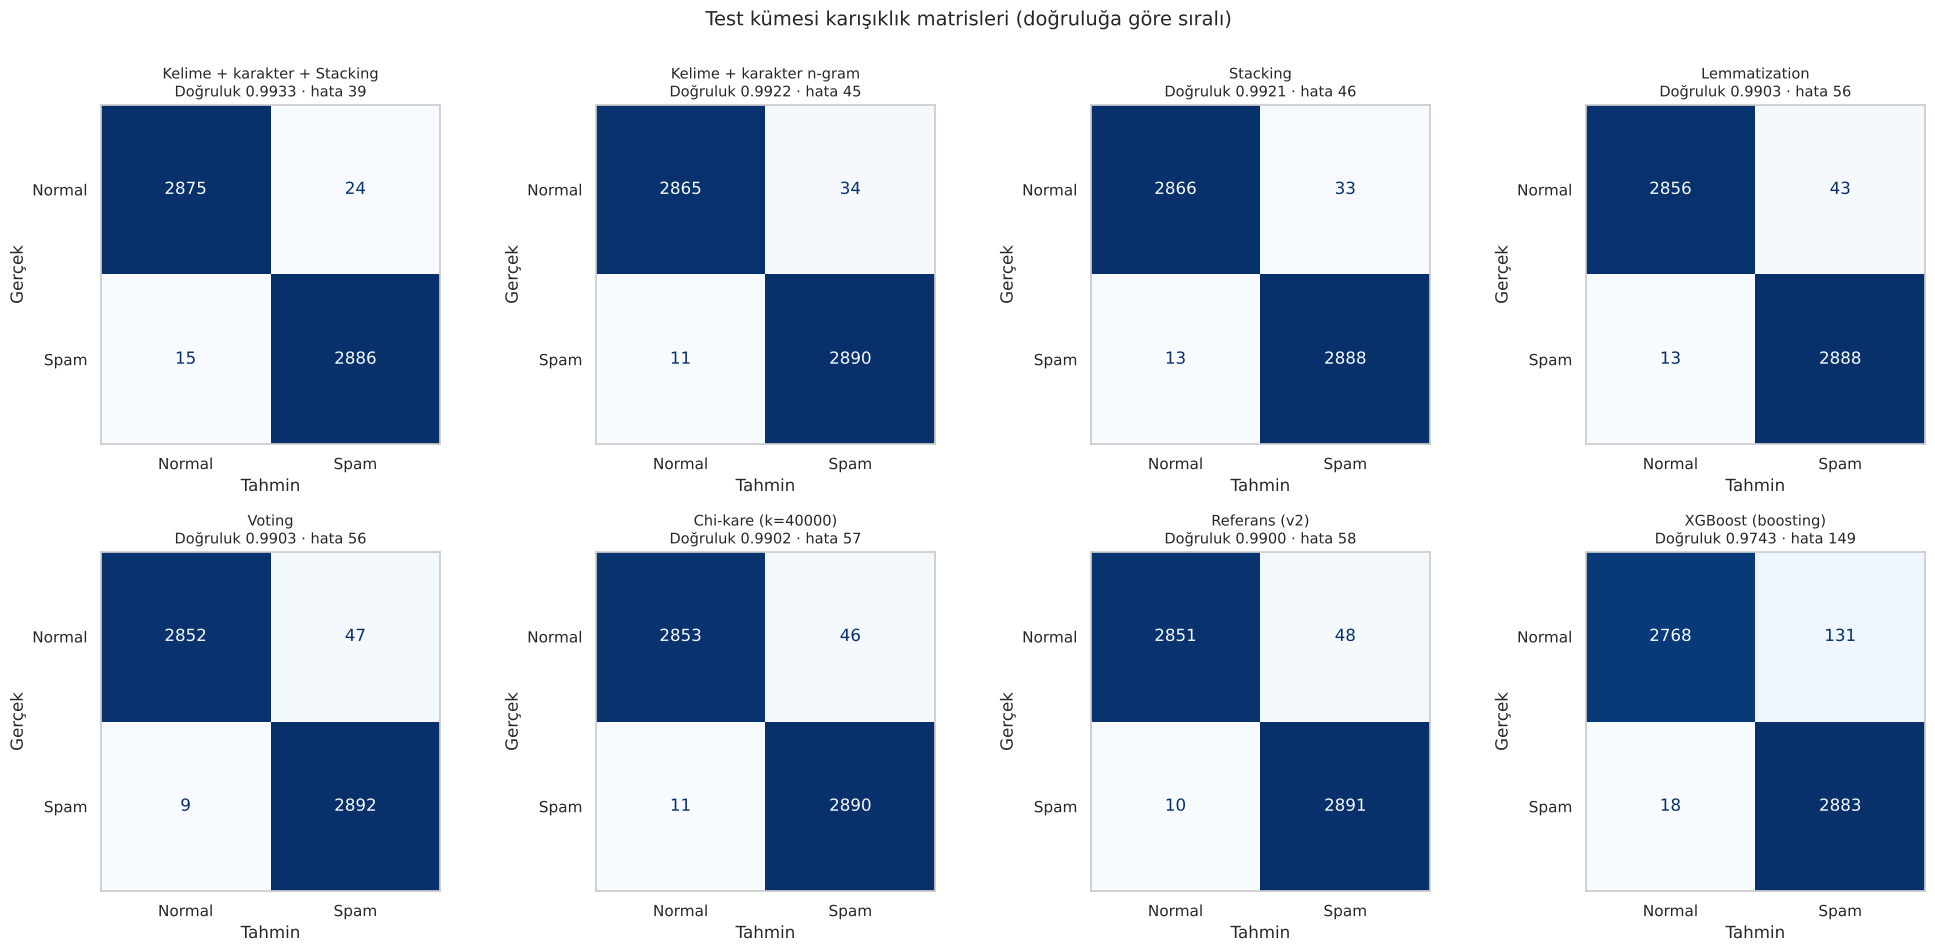

In [14]:
sirali = list(test_tablo.index)
satir = int(np.ceil(len(sirali) / 4))
fig, eksen = plt.subplots(satir, 4, figsize=(20, 4.75 * satir))
for ax, ad in zip(eksen.ravel(), sirali):
    cm = confusion_matrix(y_test, test_tahmin[ad])
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Spam"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{ad}\nDoğruluk {test_tablo.loc[ad, 'Accuracy']:.4f} · hata {cm[0,1] + cm[1,0]}", fontsize=10.5)
    ax.set_xlabel("Tahmin"); ax.set_ylabel("Gerçek"); ax.grid(False)
for ax in eksen.ravel()[len(sirali):]:
    ax.axis("off")
plt.suptitle("Test kümesi karışıklık matrisleri (doğruluğa göre sıralı)", fontsize=14, y=1.0)
plt.tight_layout(); plt.show()

### ROC eğrileri
Bütün modeller çok iyi olduğu için tam grafikte eğriler sol üst köşede üst üste biniyor. Asıl farkı görmek için sağdaki **yakınlaştırılmış** grafiğe bak. Voting sert oylama yaptığı için (sadece 0/1 oy) puan üretmez, bu yüzden ROC eğrisi yok.

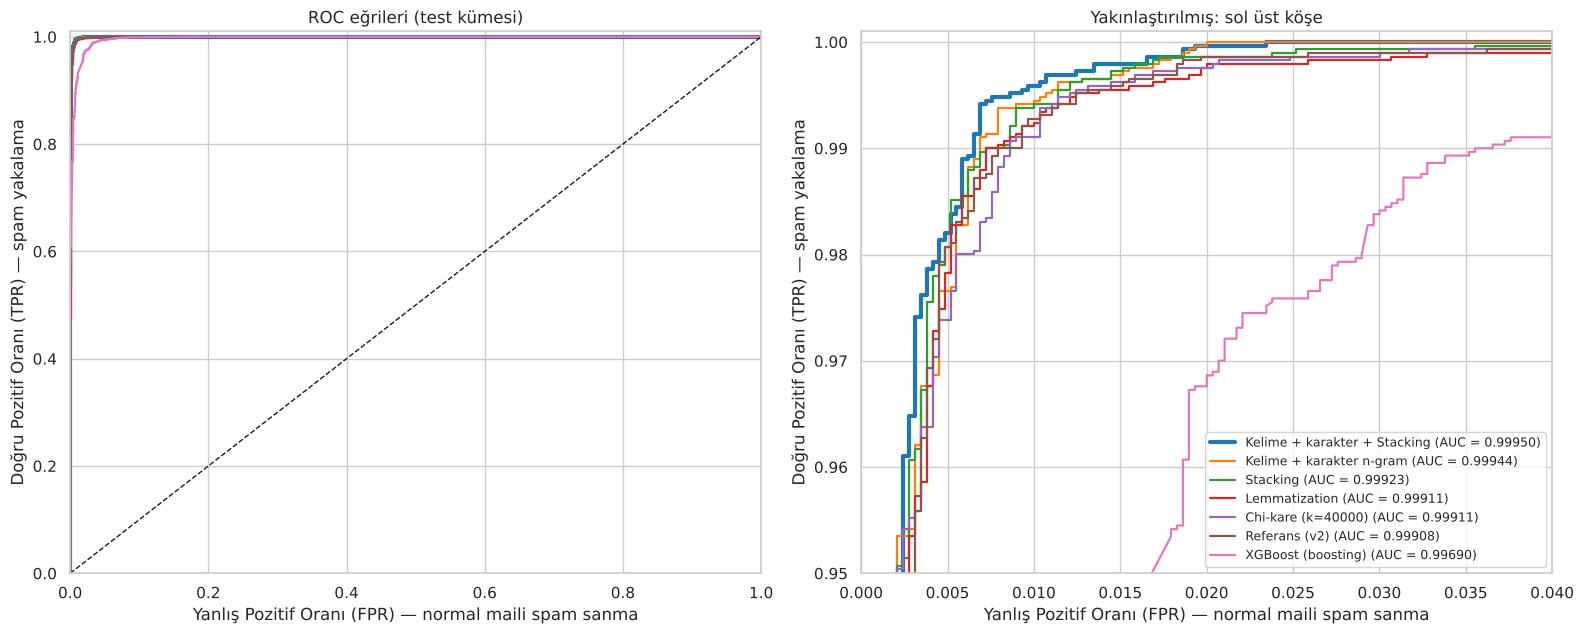

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))
renkler = dict(zip([a for a in sirali if a != "Voting"], sns.color_palette("tab10")))
for ad, renk in renkler.items():
    fpr, tpr, _ = roc_curve(y_test, test_puan[ad])
    etiket = f"{ad} (AUC = {test_tablo.loc[ad, 'ROC-AUC']:.5f})"
    kalin = 3 if ad == sirali[0] else 1.6
    for ax in (ax1, ax2):
        ax.plot(fpr, tpr, color=renk, lw=kalin, label=etiket)
ax1.plot([0, 1], [0, 1], "k--", lw=1, label="Rastgele tahmin (AUC = 0,5)")
ax1.set_xlim(0, 1); ax1.set_ylim(0, 1.01); ax1.set_title("ROC eğrileri (test kümesi)")
ax2.set_xlim(0, 0.04); ax2.set_ylim(0.95, 1.001); ax2.set_title("Yakınlaştırılmış: sol üst köşe")
for ax in (ax1, ax2):
    ax.set_xlabel("Yanlış Pozitif Oranı (FPR) — normal maili spam sanma")
    ax.set_ylabel("Doğru Pozitif Oranı (TPR) — spam yakalama")
ax2.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

### Yorum
**Test kümesi, doğrulamadaki sıralamayı doğruladı.**

- **Karışıklık matrisleri:** Kazanan model (kelime + karakter + Stacking) toplam hatayı **58'den 39'a** indiriyor (%33 azalma). En dikkat çekici değişim sağ üst hücrede: Normal e-postaların spam'e gitmesi **48'den 24'e**, yani **yarıya** düştü. Bu, v2'de en tehlikeli hata olarak belirlediğimiz türdü.
- **ROC eğrileri:** Yakınlaştırılmış grafikte kalın mavi eğri (kazanan) neredeyse **her noktada en solda ve en üstte**. Yani hangi eşik seçilirse seçilsin, daha az yanlış alarmla daha çok spam yakalıyor. AUC 0,99908'den **0,99950**'ye çıktı. XGBoost'un pembe eğrisi ise belirgin şekilde sağda kalıyor.
- **Küçük farklar:** Lemmatization, Voting ve chi-kare testte referansı çok az geçti (1–2 e-posta), ama doğrulamada geçememişti. Bu kadar küçük ve tutarsız farklar **gürültüdür**; bunlara güvenmiyoruz.
- **Voting'in ilginç bir özelliği var:** En az spam kaçıran model o (FN = 9). Ama bunu daha fazla yanlış alarmla (FP = 47) ödüyor.

Kazanan modelin üzerine v2'deki **eşik ayarı** da uygulanabilir. Böylece yanlış alarmlar daha da azaltılabilir.

> ❓ **Düşün:** Bir yöntem doğrulama kümesinde referansı geçip test kümesinde geçemezse ne düşünmeliyiz?

<details><summary><b>Cevabı göster</b> (önce kendin düşün!)</summary>

Aradaki fark muhtemelen **gürültü** düzeyindedir. Binde 1'lik bir fark, 5.800 e-postalık bir kümede 5–6 e-posta demek; rastgele bölmedeki küçük değişiklikler bile bu kadar fark yaratabilir. Bir iyileştirmeye güvenmek için **farklı kümelerde tutarlı** olması gerekir. Bu yüzden v1'de çapraz doğrulama yaptık ve burada hem doğrulama hem test sonucuna bakıyoruz.

</details>

## 🔟 Sonuç: Ödev sorusunun cevabı

**Soru:** *Doğruluk oranını hangi yöntemlerle artırabiliriz?*

In [16]:
ozet = pd.DataFrame([
    ("v1 → v2", "Tekrarları temizleme",                        "Ölçümü düzeltti (doğruluğu artırmaz, şişmiş değeri gerçeğe indirir)"),
    ("v2",      "Üçe bölme (eğitim/doğrulama/test)",            "Ayar seçimini testten ayırdı"),
    ("v2",      "Özellik sayısı deneyi",                       "30.000 → 60.000 özellik"),
    ("v2",      "Hiperparametre arama (GridSearchCV)",         "C=1'in en iyi olduğunu deneyle doğruladı"),
    ("v2",      "Eşik ayarı",                                  "Normal maillerin spam'e gitmesini yarıdan fazla azalttı"),
    ("v2",      "Çeşitli veri (Enron + SpamAssassin)",         "Başka veri setinde F1'i 0,65 → 0,96'ya çıkardı"),
    ("v2",      "Hata analizi",                                "Hatalı e-postaların belirgin şekilde kısa olduğunu gösterdi"),
] + [("v3", ad, f"Test doğruluğu {test_tablo.loc[ad, 'Accuracy']:.4f} ({test_tablo.loc[ad, 'Accuracy'] - test_tablo.loc['Referans (v2)', 'Accuracy']:+.4f}), "
                f"toplam hata {test_tablo.loc[ad, 'Toplam hata']} (referans {test_tablo.loc['Referans (v2)', 'Toplam hata']})")
     for ad in test_tablo.index if ad != "Referans (v2)"],
    columns=["Sürüm", "Yöntem", "Etkisi"])
ozet

,Sürüm,Yöntem,Etkisi
0,v1 → v2,Tekrarları temizleme,"Ölçümü düzeltti (doğruluğu artırmaz, şişmiş de..."
1,v2,Üçe bölme (eğitim/doğrulama/test),Ayar seçimini testten ayırdı
2,v2,Özellik sayısı deneyi,30.000 → 60.000 özellik
3,v2,Hiperparametre arama (GridSearchCV),C=1'in en iyi olduğunu deneyle doğruladı
4,v2,Eşik ayarı,Normal maillerin spam'e gitmesini yarıdan fazl...
5,v2,Çeşitli veri (Enron + SpamAssassin),"Başka veri setinde F1'i 0,65 → 0,96'ya çıkardı"
6,v2,Hata analizi,Hatalı e-postaların belirgin şekilde kısa oldu...
7,v3,Kelime + karakter + Stacking,"Test doğruluğu 0.9933 (+0.0033), toplam hata 3..."
8,v3,Kelime + karakter n-gram,"Test doğruluğu 0.9922 (+0.0022), toplam hata 4..."
9,v3,Stacking,"Test doğruluğu 0.9921 (+0.0021), toplam hata 4..."


### Rapora yazılabilecek sonuç paragrafı (kendi cümlelerinle düzenle)

> İlk çalışmada en iyi bulunan TF-IDF + Doğrusal SVM modelinin doğruluğunu artırmak için, literatürde spam tespitinde kullanılmış beş yöntem aynı temiz veri ve aynı eğitim/doğrulama/test bölmesi üzerinde denendi. Lemmatization ve stemming (Androutsopoulos ve ark., 2000), chi-kare özellik seçimi (Eryılmaz ve ark., 2020) ve sert oylama (Voting) belirgin bir katkı sağlamadı; XGBoost ise seyrek metin özelliklerinde doğruluğu düşürdü. Buna karşılık karakter n-gramları (Kanaris ve ark., 2006) ve Stacking (Tian ve ark., 2025; Adnan ve ark., 2024) doğruluğu ayrı ayrı yaklaşık 0,2 puan artırdı. İki yöntemin birleşimi (kelime ve karakter özellikleri üzerinde SVM, Lojistik Regresyon ve Naive Bayes'in Stacking ile birleştirilmesi) test kümesinde doğruluğu 0,9900'dan 0,9933'e, ROC-AUC'yi 0,99908'den 0,99950'ye çıkardı; toplam hata 58'den 39'a, normal e-postaların spam olarak işaretlenmesi ise 48'den 24'e indi. Literatürdeki çalışmalarla karşılaştırıldığında kazançların daha küçük olması, başlangıç modelinin zaten %99'a yakın olmasıyla açıklanabilir. Sonuçlar, literatürde başarılı bulunan bir yöntemin her koşulda işe yaramadığını ve her yöntemin kendi verimizde denenmesi gerektiğini göstermektedir. DistilBERT ile ince ayar, GPU gerektirdiği için isteğe bağlı bir deney olarak notebook'a eklenmiştir.

### Kaynaklar
- Androutsopoulos, I., Koutsias, J., Chandrinos, K. V., Paliouras, G., Spyropoulos, C. D. (2000). *An evaluation of Naive Bayesian anti-spam filtering.* https://arxiv.org/abs/cs/0006013
- Eryılmaz, E. E., Şahin, D. Ö., Kılıç, E. (2020). *Türkçe İstenmeyen E-postaların Farklı Öznitelik Seçim Yöntemleri Kullanılarak Makine Öğrenmesi Algoritmaları ile Tespit Edilmesi.* Bilgisayar Bilimleri ve Mühendisliği Dergisi, 13(2), 57–77.
- Kanaris, I., Kanaris, K., Stamatatos, E. (2006). *Spam Detection Using Character N-Grams.* SETN 2006, LNAI 3955. https://icsdweb.aegean.gr/stamatatos/papers/SETN2006.pdf
- Tian, Y., Dai, X., Li, Z., Guo, H., Mao, X. (2025). *Improving the accuracy of cybersecurity spam email detection using ensemble techniques: A stacking approach.* PLOS One 20(9): e0331574. https://pmc.ncbi.nlm.nih.gov/articles/PMC12407460
- Adnan, M., Imam, M. O., Javed, M. F., Murtza, I. (2024). *Improving spam email classification accuracy using ensemble techniques: a stacking approach.* International Journal of Information Security 23, 505–517. https://link.springer.com/article/10.1007/s10207-023-00756-1
- Asliyuksek, H., Tonkal, O., Kocaoglu, R. (2025). *A Comparative Evaluation of a Multimodal Approach for Spam Email Classification Using DistilBERT and Structural Features.* Electronics 14(19), 3855. https://www.mdpi.com/2079-9292/14/19/3855
- Sahmoud, T., Mikki, M. (2022). *Spam Detection Using BERT.* https://arxiv.org/abs/2206.02443
- Tang, Q., Li, X. (2024). *An Investigation of Large Language Models and Their Vulnerabilities in Spam Detection.* https://arxiv.org/abs/2504.09776